<a href="https://colab.research.google.com/github/Tolugold2704/Subsea-P-T-Design-Envelope-Construction_Visualization/blob/main/Case_Exercise_3_FMECA_Feature_Mapping.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###QUESTION 1: Subsea Christmas Tree (XT) FMECA Report & Analysis Summary

#### 1. FMECA Methodology & Evaluation Criteria
This Failure Mode, Effects, and Criticality Analysis (FMECA) evaluates the physical and functional barriers of a standard vertical/horizontal Subsea Christmas Tree (XT). Criticality is calculated using the Risk Priority Number (RPN):

$$\text{RPN} = \text{Severity (S)} \times \text{Occurrence (O)} \times \text{Detection (D)}$$

*   **Severity (S) [1-10]:** Evaluates the safety, environmental, and financial impact. A score of $10$ represents a catastrophic event (e.g., major hydrocarbon release or loss of well control).
*   **Occurrence (O) [1-10]:** Measures the likelihood of the failure mode occurring during the operational lifetime of the tree.
*   **Detection (D) [1-10]:** Measures the ease of detecting the failure before it results in a system-level event. Lower numbers indicate highly detectable/monitored states, while higher numbers indicate hidden or unmonitored failures.

---

#### 2. Key Insights & Criticality Rank
Based on the calculated RPNs, the failure modes are prioritized as follows:

| Rank | Component | Failure Mode | RPN | Criticality Level | Key Remediation/Controls |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **1** | Choke Valve | Severe internal erosion of choke trim | **90** | High | Acoustic sand monitoring, erosion-resistant trim insert. |
| **2** | Production Master Valve (PMV) | Fails to close on demand | **81** | High | Periodic safety valve testing (pumping), dual-barrier containment. |
| **3** | Temperature/Pressure Sensors | Signal drift (inaccurate readings) | **80** | High | Multi-sensor voting logic, dual-redundant transmitter suites. |
| **4** | Production Wing Valve (PWV) | External leakage through stem seal | **64** | Medium | Annular pressure monitoring, ROV subsea leak detection. |
| **5** | Chemical Injection Valve (CIV) | Valve plugged / blocked | **64** | Medium | Continuous chemical line flow & pressure differential monitoring. |

---

#### 3. Strategic Recommendations
*   **Erosion Management:** Because the **Choke Valve Trim Erosion** represents the highest RPN (**90**), continuous sand monitoring data must feed directly into the production control logic to choke back production dynamically if sand limits are breached.
*   **Primary Safety Barrier Verification:** PMV closures must be tested periodically in accordance with regulatory requirements (e.g., API 17D / API 14V) to confirm seal integrity.
*   **Sensor Cross-Verification:** To mitigate the high RPN of sensor drift (**80**), implement automated software-based cross-checks comparing tree pressure telemetry with downstream manifold or flowline pressure readings.

In [1]:
import pandas as pd
from IPython.display import display, HTML

# Define the FMECA data for a Subsea Christmas Tree (XT)
fmeca_data = [
    {
        "Item/Component": "Production Master Valve (PMV)",
        "Function": "Isolate production flowbore from wellbore.",
        "Failure Mode": "Fails to close on demand",
        "Failure Cause": "Actuator spring failure or scale buildup on gate",
        "Local Effect": "Loss of primary isolation barrier",
        "System Effect": "Potential uncontrolled hydrocarbon release if downstream barriers fail",
        "S (Severity)": 9,
        "O (Occurrence)": 3,
        "D (Detection)": 3,
        "Current Controls": "Periodic safety valve testing (pumping), pressure monitoring"
    },
    {
        "Item/Component": "Production Wing Valve (PWV)",
        "Function": "Control/direct flow from production bore to flowline.",
        "Failure Mode": "External leakage through stem seal",
        "Failure Cause": "Degradation of dynamic seals due to cyclic operation",
        "Local Effect": "Hydrocarbon release to marine environment",
        "System Effect": "Production shutdown, environmental contamination, emergency repair",
        "S (Severity)": 8,
        "O (Occurrence)": 4,
        "D (Detection)": 2,
        "Current Controls": "Subsea leak detection sensors, annular pressure monitoring"
    },
    {
        "Item/Component": "Subsea Control Module (SCM)",
        "Function": "Provide hydraulic & electrical control to XT valves/sensors.",
        "Failure Mode": "Loss of communication (electrical failure)",
        "Failure Cause": "Water ingress in subsea umbilical termination or electronic card failure",
        "Local Effect": "Unable to monitor telemetry or command solenoids",
        "System Effect": "Triggers fail-safe shutdown of the tree, production halt",
        "S (Severity)": 7,
        "O (Occurrence)": 4,
        "D (Detection)": 1,
        "Current Controls": "Dual-redundant channels (A & B), continuous diagnostic pinging"
    },
    {
        "Item/Component": "Choke Valve",
        "Function": "Regulate production flow rate and control drawdown pressure.",
        "Failure Mode": "Severe internal erosion of choke trim",
        "Failure Cause": "High sand production or cavitation over long periods",
        "Local Effect": "Inability to regulate flow control accurately",
        "System Effect": "Damage to downstream flowline, potential sand erosion of headers",
        "S (Severity)": 6,
        "O (Occurrence)": 5,
        "D (Detection)": 3,
        "Current Controls": "Acoustic sand detectors, downstream pressure monitoring"
    },
    {
        "Item/Component": "Tree Connector",
        "Function": "Structural and pressure connection between XT and Wellhead.",
        "Failure Mode": "Gasket profile leak (AX/VX gasket)",
        "Failure Cause": "Improper makeup torque, lock ring relaxation, or corrosion",
        "Local Effect": "Hydrocarbon bypass to ambient sea",
        "System Effect": "Major safety/environmental hazard, complete field intervention required",
        "S (Severity)": 10,
        "O (Occurrence)": 2,
        "D (Detection)": 2,
        "Current Controls": "Visual ROV inspection, gasket cavity pressure monitoring"
    },
    {
        "Item/Component": "Chemical Injection Valve (CIV)",
        "Function": "Inject scale/hydrate inhibitors into production stream.",
        "Failure Mode": "Valve plugged/blocked",
        "Failure Cause": "Chemical precipitation or particulate contamination in injection fluid",
        "Local Effect": "Loss of chemical delivery",
        "System Effect": "Rapid hydrate formation, leading to blockage of flowline",
        "S (Severity)": 8,
        "O (Occurrence)": 4,
        "D (Detection)": 2,
        "Current Controls": "Line flow meters, chemical line pressure transmitters"
    },
    {
        "Item/Component": "Temperature/Pressure Sensors (P/T)",
        "Function": "Monitor production fluid conditions within the flowbore.",
        "Failure Mode": "Signal drift (inaccurate readings)",
        "Failure Cause": "Sensor aging, scaling, or electronic degradation",
        "Local Effect": "Erronous telemetry sent to SCM",
        "System Effect": "Incorrect reservoir management decisions, false alarms",
        "S (Severity)": 5,
        "O (Occurrence)": 4,
        "D (Detection)": 4,
        "Current Controls": "Cross-referencing with downstream/subsea manifold sensors"
    },
    {
        "Item/Component": "Surface Controlled Subsurface Safety Valve (SCSSV) Control Line",
        "Function": "Deliver hydraulic pressure to actuate the downhole safety valve.",
        "Failure Mode": "Hydraulic fluid leakage/loss of pressure",
        "Failure Cause": "Fitting corrosion, physical damage during XT landing",
        "Local Effect": "Downhole valve closes automatically (fail-safe)",
        "System Effect": "Well shut-in, inability to reopen SCSSV without intervention",
        "S (Severity)": 7,
        "O (Occurrence)": 3,
        "D (Detection)": 2,
        "Current Controls": "Hydraulic flow meters in SCM, pressure decay tests"
    },
    {
        "Item/Component": "Workover Control System (WOCS) Connector",
        "Function": "Provide intervention hydraulic interfaces.",
        "Failure Mode": "Stuck intervention valve (cannot isolate stab port)",
        "Failure Cause": "Debris accumulation, marine growth in the ROV panel receptacle",
        "Local Effect": "Unable to decouple or isolate intervention lines safely",
        "System Effect": "Delays in workover, risk of environmental leakage during disconnect",
        "S (Severity)": 6,
        "O (Occurrence)": 3,
        "D (Detection)": 3,
        "Current Controls": "ROV dust caps, regular protective covers, glycol flushing"
    },
    {
        "Item/Component": "Annulus Master Valve (AMV)",
        "Function": "Isolate the well casing annulus from the subsea tree.",
        "Failure Mode": "External actuator housing leak (hydraulic fluid)",
        "Failure Cause": "Dynamic seal failure under high hydrostatic pressure",
        "Local Effect": "Minor control fluid release to sea, loss of hydraulic system volume",
        "System Effect": "Depletion of HPU reservoir on top-side facility, potential slow valve operation",
        "S (Severity)": 5,
        "O (Occurrence)": 4,
        "D (Detection)": 2,
        "Current Controls": "Biodegradable control fluid, SCM flow monitoring"
    }
]

# Create DataFrame
df = pd.DataFrame(fmeca_data)

# Calculate Risk Priority Number (RPN)
df['RPN'] = df['S (Severity)'] * df['O (Occurrence)'] * df['D (Detection)']

# Sort by RPN to prioritize high-risk items
df = df.sort_values(by='RPN', ascending=False).reset_index(drop=True)

# Apply custom styling to the DataFrame for high-quality representation
styled_df = df.style.set_properties(**{
    'text-align': 'left',
    'border-color': 'lightgrey'
}).set_table_styles([
    dict(selector='th', props=[('background-color', '#1f4e79'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center')]),
    dict(selector='tr:nth-child(even)', props=[('background-color', '#f2f2f2')]),
    dict(selector='tr:hover', props=[('background-color', '#e6f2ff')])
]).bar(subset=['RPN'], color='#ff9999', vmin=0, vmax=200)

# Display the structured table
display(HTML("<h3>Subsea Christmas Tree FMECA Worksheet</h3>"))
display(styled_df)


,Item/Component,Function,Failure Mode,Failure Cause,Local Effect,System Effect,S (Severity),O (Occurrence),D (Detection),Current Controls,RPN
0,Choke Valve,Regulate production flow rate and control drawdown pressure.,Severe internal erosion of choke trim,High sand production or cavitation over long periods,Inability to regulate flow control accurately,"Damage to downstream flowline, potential sand erosion of headers",6,5,3,"Acoustic sand detectors, downstream pressure monitoring",90
1,Production Master Valve (PMV),Isolate production flowbore from wellbore.,Fails to close on demand,Actuator spring failure or scale buildup on gate,Loss of primary isolation barrier,Potential uncontrolled hydrocarbon release if downstream barriers fail,9,3,3,"Periodic safety valve testing (pumping), pressure monitoring",81
2,Temperature/Pressure Sensors (P/T),Monitor production fluid conditions within the flowbore.,Signal drift (inaccurate readings),"Sensor aging, scaling, or electronic degradation",Erronous telemetry sent to SCM,"Incorrect reservoir management decisions, false alarms",5,4,4,Cross-referencing with downstream/subsea manifold sensors,80
3,Production Wing Valve (PWV),Control/direct flow from production bore to flowline.,External leakage through stem seal,Degradation of dynamic seals due to cyclic operation,Hydrocarbon release to marine environment,"Production shutdown, environmental contamination, emergency repair",8,4,2,"Subsea leak detection sensors, annular pressure monitoring",64
4,Chemical Injection Valve (CIV),Inject scale/hydrate inhibitors into production stream.,Valve plugged/blocked,Chemical precipitation or particulate contamination in injection fluid,Loss of chemical delivery,"Rapid hydrate formation, leading to blockage of flowline",8,4,2,"Line flow meters, chemical line pressure transmitters",64
5,Workover Control System (WOCS) Connector,Provide intervention hydraulic interfaces.,Stuck intervention valve (cannot isolate stab port),"Debris accumulation, marine growth in the ROV panel receptacle",Unable to decouple or isolate intervention lines safely,"Delays in workover, risk of environmental leakage during disconnect",6,3,3,"ROV dust caps, regular protective covers, glycol flushing",54
6,Surface Controlled Subsurface Safety Valve (SCSSV) Control Line,Deliver hydraulic pressure to actuate the downhole safety valve.,Hydraulic fluid leakage/loss of pressure,"Fitting corrosion, physical damage during XT landing",Downhole valve closes automatically (fail-safe),"Well shut-in, inability to reopen SCSSV without intervention",7,3,2,"Hydraulic flow meters in SCM, pressure decay tests",42
7,Tree Connector,Structural and pressure connection between XT and Wellhead.,Gasket profile leak (AX/VX gasket),"Improper makeup torque, lock ring relaxation, or corrosion",Hydrocarbon bypass to ambient sea,"Major safety/environmental hazard, complete field intervention required",10,2,2,"Visual ROV inspection, gasket cavity pressure monitoring",40
8,Annulus Master Valve (AMV),Isolate the well casing annulus from the subsea tree.,External actuator housing leak (hydraulic fluid),Dynamic seal failure under high hydrostatic pressure,"Minor control fluid release to sea, loss of hydraulic system volume","Depletion of HPU reservoir on top-side facility, potential slow valve operation",5,4,2,"Biodegradable control fluid, SCM flow monitoring",40
9,Subsea Control Module (SCM),Provide hydraulic & electrical control to XT valves/sensors.,Loss of communication (electrical failure),Water ingress in subsea umbilical termination or electronic card failure,Unable to monitor telemetry or command solenoids,"Triggers fail-safe shutdown of the tree, production halt",7,4,1,"Dual-redundant channels (A & B), continuous diagnostic pinging",28


### QUESTION 2: Physics-of-Failure & ML Feature Engineering Mapping

To build predictive maintenance models (Prognostics and Health Management) for our Subsea Christmas Tree, we must bridge the gap between qualitative FMECA failure modes and quantifiable sensor-driven physical parameters. Below is the mapping of each failure mode to its driving physics parameters and corresponding Machine Learning (ML) feature engineering strategies.

In [2]:
import pandas as pd
from IPython.display import display, HTML

physics_ml_data = [
    {
        "Component": "Production Master Valve (PMV)",
        "Failure Mode": "Fails to close on demand",
        "Driving Physics Parameters": "Actuator spring compression force, gate friction, hydraulic pressure drop rate, fluid viscosity/wax deposition.",
        "ML Feature Engineering Strategies": "**Time-to-Stroke (tts):** Delta time between SCM solenoid command and limit switch activation. **Pressure Decay Rate:** Dynamic slope (dP/dt) of the hydraulic supply pressure during actuator stroke. **Frictional Force Estimation:** Rolling mean of actuation pressure signatures over time."
    },
    {
        "Component": "Production Wing Valve (PWV)",
        "Failure Mode": "External leakage through stem seal",
        "Driving Physics Parameters": "Differential pressure across packing, local sea-water temperature, stem cycle count (wear index), structural stress.",
        "ML Feature Engineering Strategies": "**Accumulated Travel Index:** Cumulative sum of stem displacement. **Barrier Leakage Indicators:** Phase correlation between cyclic pressure variations in the valve annulus and the production bore."
    },
    {
        "Component": "Subsea Control Module (SCM)",
        "Failure Mode": "Loss of communication (electrical failure)",
        "Driving Physics Parameters": "Dielectric strength of umbilical insulation, moisture ingress rate, voltage drop, thermal expansion of electronics.",
        "ML Feature Engineering Strategies": "**Impedance Degradation Profile:** High-frequency rolling standard deviation of line insulation resistance. **Signal-to-Noise Ratio (SNR):** Rolling mean SNR of telemetry carrier packets."
    },
    {
        "Component": "Choke Valve",
        "Failure Mode": "Severe internal erosion of choke trim",
        "Driving Physics Parameters": "Fluid velocity, sand mass flow rate (impact kinetic energy), trim material shear strength, cavitation index.",
        "ML Feature Engineering Strategies": "**Cumulative Sand Exposure:** Time-integrated product of sand concentration (from acoustic detectors) and flow rate. **Cv Deviation:** Real-time deviation of actual flow coefficient ($C_v$) from the manufacturer's nominal valve characteristic curve."
    },
    {
        "Component": "Tree Connector",
        "Failure Mode": "Gasket profile leak (AX/VX gasket)",
        "Driving Physics Parameters": "Bending moment from riser/tensioners, gasket seating stress, galvanic corrosion rate, fluid thermal expansion.",
        "ML Feature Engineering Strategies": "**Load Coupling Features:** Coherence metrics between environmental wave spectra (from ADCPs) and subsea pressure fluctuations. **Delta-P Trend:** Multi-day exponential moving average of gasket cavity pressure."
    },
    {
        "Component": "Chemical Injection Valve (CIV)",
        "Failure Mode": "Valve plugged/blocked",
        "Driving Physics Parameters": "Chemical shear rate, fluid temperature (hydrate stability curve), particulate deposition rate, differential pressure.",
        "ML Feature Engineering Strategies": "**Hydrate Risk Index:** Calculated distance between the current operational P-T state and the theoretical hydrate envelope boundary. **Hydraulic Resistance ($R_h$):** Dynamic ratio of line differential pressure to injection flow rate."
    },
    {
        "Component": "Temperature/Pressure Sensors (P/T)",
        "Failure Mode": "Signal drift (inaccurate readings)",
        "Driving Physics Parameters": "Thermocouple aging, piezoresistive element fatigue, sensor cavity fouling.",
        "ML Feature Engineering Strategies": "**Analytical Redundancy Residuals:** Reconstruction error from an Autoencoder model trained only on highly-correlated physical variables. **Sensor-to-Sensor Coherence:** High-frequency cross-correlation coefficient between neighboring redundant sensor channels."
    },
    {
        "Component": "SCSSV Control Line",
        "Failure Mode": "Hydraulic fluid leakage/loss of pressure",
        "Driving Physics Parameters": "Viscous fluid flow through micro-orifices, mechanical fatigue of tubing, hydrostatic head pressure.",
        "ML Feature Engineering Strategies": "**Volume Balance Margin:** Delta between hydraulic fluid pumped at the surface HPU and volume received at the subsea accumulator. **Transient Decay Analysis:** Wavelet transform coefficients of hydraulic pressure pulses during downhole valve actuation."
    },
    {
        "Component": "WOCS Connector",
        "Failure Mode": "Stuck intervention valve",
        "Driving Physics Parameters": "Marine growth rate, shear resistance of debris, latching piston hydraulic force.",
        "ML Feature Engineering Strategies": "**Static Breakout Pressure:** Peak hydraulic pressure required to initiate the first 1% of valve displacement. **Idle Time Feature:** Days elapsed since last ROV intervention cycle."
    },
    {
        "Component": "Annulus Master Valve (AMV)",
        "Failure Mode": "External actuator housing leak",
        "Driving Physics Parameters": "Ambient sea-water hydrostatic pressure, hydraulic oil compressibility, elastomeric seal relaxation.",
        "ML Feature Engineering Strategies": "**Pump Duty Cycle:** Exponentially weighted moving average of SCM pilot pump activation frequency. **Ambient Thermal Compensation:** Normalizing control fluid pressure against localized bottom-sea temperature changes."
    }
]

# Create and style DataFrame
physics_df = pd.DataFrame(physics_ml_data)

styled_physics_df = physics_df.style.set_properties(**{
    'text-align': 'left',
    'border-color': 'lightgrey'
}).set_table_styles([
    dict(selector='th', props=[('background-color', '#2b5b84'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center')]),
    dict(selector='tr:nth-child(even)', props=[('background-color', '#f9fbfd')]),
    dict(selector='tr:hover', props=[('background-color', '#e1f0fa')])
])

display(HTML("<h4>FMECA Physics & ML Feature Engineering Matrix</h4>"))
display(styled_physics_df)


,Component,Failure Mode,Driving Physics Parameters,ML Feature Engineering Strategies
0,Production Master Valve (PMV),Fails to close on demand,"Actuator spring compression force, gate friction, hydraulic pressure drop rate, fluid viscosity/wax deposition.",**Time-to-Stroke (tts):** Delta time between SCM solenoid command and limit switch activation. **Pressure Decay Rate:** Dynamic slope (dP/dt) of the hydraulic supply pressure during actuator stroke. **Frictional Force Estimation:** Rolling mean of actuation pressure signatures over time.
1,Production Wing Valve (PWV),External leakage through stem seal,"Differential pressure across packing, local sea-water temperature, stem cycle count (wear index), structural stress.",**Accumulated Travel Index:** Cumulative sum of stem displacement. **Barrier Leakage Indicators:** Phase correlation between cyclic pressure variations in the valve annulus and the production bore.
2,Subsea Control Module (SCM),Loss of communication (electrical failure),"Dielectric strength of umbilical insulation, moisture ingress rate, voltage drop, thermal expansion of electronics.",**Impedance Degradation Profile:** High-frequency rolling standard deviation of line insulation resistance. **Signal-to-Noise Ratio (SNR):** Rolling mean SNR of telemetry carrier packets.
3,Choke Valve,Severe internal erosion of choke trim,"Fluid velocity, sand mass flow rate (impact kinetic energy), trim material shear strength, cavitation index.",**Cumulative Sand Exposure:** Time-integrated product of sand concentration (from acoustic detectors) and flow rate. **Cv Deviation:** Real-time deviation of actual flow coefficient ($C_v$) from the manufacturer's nominal valve characteristic curve.
4,Tree Connector,Gasket profile leak (AX/VX gasket),"Bending moment from riser/tensioners, gasket seating stress, galvanic corrosion rate, fluid thermal expansion.",**Load Coupling Features:** Coherence metrics between environmental wave spectra (from ADCPs) and subsea pressure fluctuations. **Delta-P Trend:** Multi-day exponential moving average of gasket cavity pressure.
5,Chemical Injection Valve (CIV),Valve plugged/blocked,"Chemical shear rate, fluid temperature (hydrate stability curve), particulate deposition rate, differential pressure.",**Hydrate Risk Index:** Calculated distance between the current operational P-T state and the theoretical hydrate envelope boundary. **Hydraulic Resistance ($R_h$):** Dynamic ratio of line differential pressure to injection flow rate.
6,Temperature/Pressure Sensors (P/T),Signal drift (inaccurate readings),"Thermocouple aging, piezoresistive element fatigue, sensor cavity fouling.",**Analytical Redundancy Residuals:** Reconstruction error from an Autoencoder model trained only on highly-correlated physical variables. **Sensor-to-Sensor Coherence:** High-frequency cross-correlation coefficient between neighboring redundant sensor channels.
7,SCSSV Control Line,Hydraulic fluid leakage/loss of pressure,"Viscous fluid flow through micro-orifices, mechanical fatigue of tubing, hydrostatic head pressure.",**Volume Balance Margin:** Delta between hydraulic fluid pumped at the surface HPU and volume received at the subsea accumulator. **Transient Decay Analysis:** Wavelet transform coefficients of hydraulic pressure pulses during downhole valve actuation.
8,WOCS Connector,Stuck intervention valve,"Marine growth rate, shear resistance of debris, latching piston hydraulic force.",**Static Breakout Pressure:** Peak hydraulic pressure required to initiate the first 1% of valve displacement. **Idle Time Feature:** Days elapsed since last ROV intervention cycle.
9,Annulus Master Valve (AMV),External actuator housing leak,"Ambient sea-water hydrostatic pressure, hydraulic oil compressibility, elastomeric seal relaxation.",**Pump Duty Cycle:** Exponentially weighted moving average of SCM pilot pump activation frequency. **Ambient Thermal Compensation:** Normalizing control fluid pressure against localized bottom-sea t

### QUESTION 3: Implementation & Validation of Physics-of-Failure Models

We will implement and validate two specific physics-of-failure models:

1. **Choke Valve Sand Erosion Model:**
   Calculates the material removal rate ($ER$ in mm/year) using a classic empirical model:
   $$ER = K \cdot C_{sand} \cdot Q_{fluid} \cdot v^2$$
   where $K$ is the wear coefficient ($1.5 \times 10^{-6}$), $C_{sand}$ is sand concentration in ppm, $Q_{fluid}$ is fluid flow rate in $m^3/day$, and $v$ is fluid velocity in $m/s$.

2. **Chemical Injection Valve Hydrate Formation Risk (Temperature Margin):**
   Calculates the hydrate dissociation temperature ($T_{hyd}$ in °C) for a given pressure ($P$ in bar) using the classic Adisasmito-Sloan equation:
   $$T_{hyd} = a \cdot \ln(P) + b$$
   where for natural gas $a = 8.13$ and $b = -15.4$. The Hydrate Risk Margin is $\Delta T = T_{fluid} - T_{hyd}$. A negative margin indicates active hydrate risk.

In [3]:
import numpy as np

# --- Model 1: Choke Valve Sand Erosion ---
def calculate_erosion_rate(c_sand, q_fluid, velocity, K=1.5e-6):
    """
    Calculate erosion rate in mm/year.
    c_sand: sand concentration in ppm
    q_fluid: flow rate in m3/day
    velocity: fluid velocity in m/s
    """
    return K * c_sand * q_fluid * (velocity ** 2)

# --- Model 2: Hydrate Formation Risk ---
def calculate_hydrate_margin(t_fluid, pressure_bar):
    """
    Calculates the temperature safety margin against hydrate formation.
    t_fluid: Fluid temperature in °C
    pressure_bar: Annular/bore pressure in bar
    """
    # Adisasmito-Sloan simplified correlation parameters for methane hydrates
    a = 8.13
    b = -15.4
    t_hydrate = a * np.log(pressure_bar) + b
    margin = t_fluid - t_hydrate
    return t_hydrate, margin

# --- Validation & Hand Calculations ---
print("=== MODEL 1: CHOKE VALVE EROSION VALIDATION ===")
# Inputs for Hand Calculation:
# c_sand = 50 ppm, q_fluid = 1200 m3/day, velocity = 15 m/s
# Hand Calc: ER = 1.5e-6 * 50 * 1200 * (15^2) = 1.5e-6 * 50 * 1200 * 225 = 20.25 mm/year

c_sand, q_fluid, velocity = 50.0, 1200.0, 15.0
er_model = calculate_erosion_rate(c_sand, q_fluid, velocity)
er_hand = 20.25

print(f"Inputs -> Sand Conc: {c_sand} ppm, Flow: {q_fluid} m3/day, Velocity: {velocity} m/s")
print(f"Python Model Result: {er_model:.4f} mm/year")
print(f"Hand Calc Result:   {er_hand:.4f} mm/year")
print(f"Validation Match:    {np.isclose(er_model, er_hand)}\n")

print("=== MODEL 2: HYDRATE MARGIN VALIDATION ===")
# Inputs for Hand Calculation:
# t_fluid = 12.0 °C, pressure_bar = 80.0 bar
# Hand Calc:
# t_hydrate = 8.13 * ln(80) - 15.4 = 8.13 * 4.3820 - 15.4 = 35.6259 - 15.4 = 20.2259 °C
# margin = 12.0 - 20.2259 = -8.2259 °C (High Risk)

t_fluid, pressure_bar = 12.0, 80.0
t_hyd_model, margin_model = calculate_hydrate_margin(t_fluid, pressure_bar)
t_hyd_hand = 20.2259
margin_hand = -8.2259

print(f"Inputs -> Fluid Temp: {t_fluid} °C, Pressure: {pressure_bar} bar")
print(f"Python Model Hydrate Temp: {t_hyd_model:.4f} °C, Margin: {margin_model:.4f} °C")
print(f"Hand Calc Hydrate Temp:   {t_hyd_hand:.4f} °C, Margin: {margin_hand:.4f} °C")
print(f"Validation Match:          {np.isclose(t_hyd_model, t_hyd_hand, atol=1e-4)}")


=== MODEL 1: CHOKE VALVE EROSION VALIDATION ===
Inputs -> Sand Conc: 50.0 ppm, Flow: 1200.0 m3/day, Velocity: 15.0 m/s
Python Model Result: 20.2500 mm/year
Hand Calc Result:   20.2500 mm/year
Validation Match:    True

=== MODEL 2: HYDRATE MARGIN VALIDATION ===
Inputs -> Fluid Temp: 12.0 °C, Pressure: 80.0 bar
Python Model Hydrate Temp: 20.2259 °C, Margin: -8.2259 °C
Hand Calc Hydrate Temp:   20.2259 °C, Margin: -8.2259 °C
Validation Match:          True


### QUESTION 4: FMECA Risk Matrix Visualization (Severity vs. Occurrence)

We will now construct a standard visual risk matrix mapping each failure mode based on its **Severity** (Y-axis) and **Occurrence** (X-axis). The points are labeled, and the background is colored to represent risk thresholds (low, medium, high), with the size and color of each point corresponding to its calculated **RPN** value.

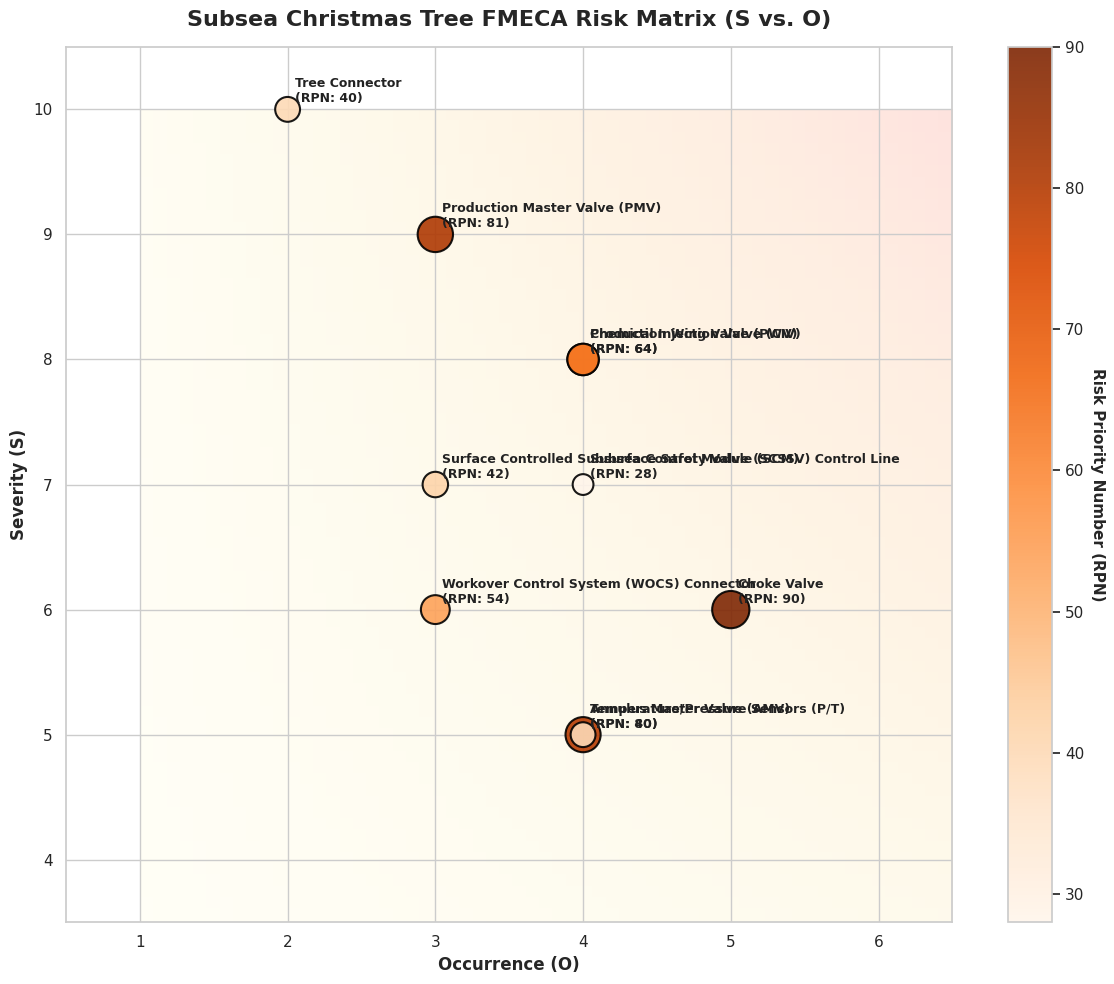

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Prepare the data from our original FMECA dataframe
plot_df = df.copy()

# Create the figure and axes
plt.figure(figsize=(12, 10))
sns.set_theme(style="whitegrid")

# Create a background grid showing typical Risk Zones (Green, Yellow, Red)
# We'll create a 2D grid overlay using helper coordinate values
x_grid, y_grid = np.meshgrid(np.linspace(1, 10, 100), np.linspace(1, 10, 100))
z_rpn = x_grid * y_grid  # Product representing Severity x Occurrence

# Plot the risk contours in the background
plt.imshow(z_rpn, extent=[1, 10, 1, 10], origin='lower', cmap='YlOrRd', alpha=0.15, aspect='auto')

# Plot the failure modes
scatter = plt.scatter(
    x=plot_df['O (Occurrence)'],
    y=plot_df['S (Severity)'],
    s=plot_df['RPN'] * 8,              # Point size proportional to RPN
    c=plot_df['RPN'],                  # Color mapped to RPN
    cmap='Oranges',
    edgecolors='black',
    linewidths=1.5,
    alpha=0.9,
    zorder=3
)

# Annotate each point with the component name and RPN
for idx, row in plot_df.iterrows():
    short_label = f"{row['Item/Component']}\n(RPN: {row['RPN']})"
    plt.annotate(
        short_label,
        xy=(row['O (Occurrence)'], row['S (Severity)']),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=9,
        fontweight='bold',
        color='#222222',
        zorder=4
    )

# Customize plot elements
plt.title('Subsea Christmas Tree FMECA Risk Matrix (S vs. O)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Occurrence (O)', fontsize=12, fontweight='bold')
plt.ylabel('Severity (S)', fontsize=12, fontweight='bold')
plt.xlim(0.5, 6.5)
plt.ylim(3.5, 10.5)
plt.xticks(range(1, 7))
plt.yticks(range(4, 11))

# Add a colorbar indicating RPN values
cbar = plt.colorbar(scatter)
cbar.set_label('Risk Priority Number (RPN)', rotation=270, labelpad=15, fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()